# COMP4318/5318 Assignment 2: Image Classification

### Group number: ...  , SID1: ... , SID2: ..., SID3: ..., SID4: ... 

This template notebook includes code to load the  dataset and a skeleton for the main sections that should be included in the notebook. Please stick to this struture for your submitted notebook.

Please focus on making your code clear, with appropriate variable names and whitespace. Include comments and markdown text to aid the readability of your code where relevant. See the specification and marking criteria in the associated specification to guide you when completing your implementation.

## Setup and dependencies
Please use this section to list and set up all your required libraries/dependencies and your plotting environment.

This notebook was run locally (CPU only) with Python 3.11 and:

| Library | Version | Use |
| --- | --- | --- |
| keras | 3.15.1 | CNN definition and training (TensorFlow backend) |
| tensorflow | 2.21.0 | Keras backend |
| scikit-learn | 1.9.1 | Train/validation split, parameter grid, metrics |
| numpy | 2.4.6 | Array handling |
| pandas | 3.1.0 | Result tables and CSV export |
| matplotlib | 3.11.2 | Plots |

In [1]:
# File paths and runtime measurement
import os
from pathlib import Path
from time import perf_counter

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # hide TensorFlow start-up messages

# Data handling and visualisation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Neural network (Keras 3 with the TensorFlow backend)
import keras
from keras import layers

# Data split, hyperparameter search, and evaluation
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

print("Keras:", keras.__version__, "| backend:", keras.backend.backend())

# Random seed for reproducibility (same seed as the other members)
SEED_CNN = 42
keras.utils.set_random_seed(SEED_CNN)

# CSV files shared with the rest of the group are written here
RESULTS_DIR_CNN = Path("results_cnn")
RESULTS_DIR_CNN.mkdir(exist_ok=True)

Keras: 3.15.1 | backend: tensorflow


## 1. Data loading, exploration, and preprocessing


Code to load the dataset is provided in the following cell. Please proceed with your data exploration and preprocessing in the remainder of this section.

In [2]:
# Load the dataset training and test sets as numpy arrays.
# The template expects the Assignment2Data folder next to the notebook;
# the second location matches the unzipped Canvas download.
DATA_CANDIDATES_CNN = [
    Path("Assignment2Data"),
    Path("Assignment2Data-1") / "Assignment2Data",
]
DATA_DIR_CNN = next(
    path for path in DATA_CANDIDATES_CNN if (path / "X_train.npy").exists()
)

X_train_all_cnn = np.load(DATA_DIR_CNN / "X_train.npy", allow_pickle=False)
y_train_all_cnn = np.load(
    DATA_DIR_CNN / "y_train.npy", allow_pickle=False
).astype("int64").ravel()
X_test_img_cnn = np.load(DATA_DIR_CNN / "X_test.npy", allow_pickle=False)
y_test_cnn = np.load(
    DATA_DIR_CNN / "y_test.npy", allow_pickle=False
).astype("int64").ravel()

# PathMNIST class names (MedMNIST v2)
CLASS_NAMES_CNN = [
    "adipose",
    "background",
    "debris",
    "lymphocytes",
    "mucus",
    "smooth muscle",
    "normal colon mucosa",
    "cancer-assoc. stroma",
    "colorectal adenocarcinoma epith.",
]
NUM_CLASSES_CNN = len(CLASS_NAMES_CNN)
INPUT_SHAPE_CNN = X_train_all_cnn.shape[1:]

print("Training images:", X_train_all_cnn.shape, X_train_all_cnn.dtype)
print("Test images:", X_test_img_cnn.shape, X_test_img_cnn.dtype)
print("Number of classes:", NUM_CLASSES_CNN)

Training images: (32000, 28, 28, 3) uint8
Test images: (8000, 28, 28, 3) uint8
Number of classes: 9


#### Training/validation split for the CNN

The CNN uses the **original 28×28×3 images**, not Member A's 357 extracted features: the features summarise colour per block and lose the pixel layout that convolutions rely on.

To keep the comparison fair, the CNN is tuned on **the same stratified 80/20 split as the other two models** (25,600 training and 6,400 validation images). The split is recreated with the same call and seed Member A used, so this notebook does not depend on any extra files. If the shared `split_indices.npz` file is present, the cell checks that the indices match.

In [3]:
# Recreate Member A's stratified split (same function, test size, and seed).
fit_idx_cnn, val_idx_cnn = train_test_split(
    np.arange(len(y_train_all_cnn)),
    test_size=0.2,
    stratify=y_train_all_cnn,
    random_state=SEED_CNN,
)

# Optional check against the shared split file, if it is available.
for split_path in [Path("split_indices.npz"), Path("data") / "split_indices.npz"]:
    if split_path.exists():
        with np.load(split_path, allow_pickle=False) as shared_split:
            assert np.array_equal(fit_idx_cnn, shared_split["fit_idx"])
            assert np.array_equal(val_idx_cnn, shared_split["val_idx"])
        print("Split matches", split_path)
        break

print("Training subset:", len(fit_idx_cnn))
print("Validation subset:", len(val_idx_cnn))

Training subset: 25600
Validation subset: 6400


#### CNN preprocessing

The only preprocessing applied for the CNN is converting the `uint8` pixels to `float32` and dividing by 255, so every value lies in [0, 1]. The (28, 28, 3) layout is kept because convolutional filters need neighbouring pixels to stay next to each other.

- **No learned statistics.** Scaling by 255 is a fixed operation, so nothing is fitted on the data and there is no risk of leaking validation or test information.
- **Per-channel standardisation was considered but not used.** Subtracting each channel's training mean and dividing by its standard deviation is only a fixed linear rescaling, which the weights and biases of the first convolution can absorb. Inputs in [0, 1] already train stably with Adam, and leaving them unstandardised avoids fitting extra statistics.
- **No resizing, cropping or flattening.** The images are already small and centred tissue patches.
- **Data augmentation (flips/rotations) was considered but not used.** It would multiply the training time on a CPU, and the aim is to compare the three algorithms under similar conditions.

In [4]:
def preprocess_cnn(images):
    """Scale uint8 RGB pixels to [0, 1] float32, keeping the image layout."""
    return images.astype("float32") / 255.0


X_fit_cnn = preprocess_cnn(X_train_all_cnn[fit_idx_cnn])
y_fit_cnn = y_train_all_cnn[fit_idx_cnn]

X_val_cnn = preprocess_cnn(X_train_all_cnn[val_idx_cnn])
y_val_cnn = y_train_all_cnn[val_idx_cnn]

print("Training subset:", X_fit_cnn.shape, X_fit_cnn.dtype)
print("Validation subset:", X_val_cnn.shape, X_val_cnn.dtype)

Training subset: (25600, 28, 28, 3) float32
Validation subset: (6400, 28, 28, 3) float32


### Examples of preprocessed data
Please print/display some examples of your preprocessed data here.

Pixel range: [0.0, 1.0]
Per-channel mean (R, G, B): [0.836 0.541 0.789]


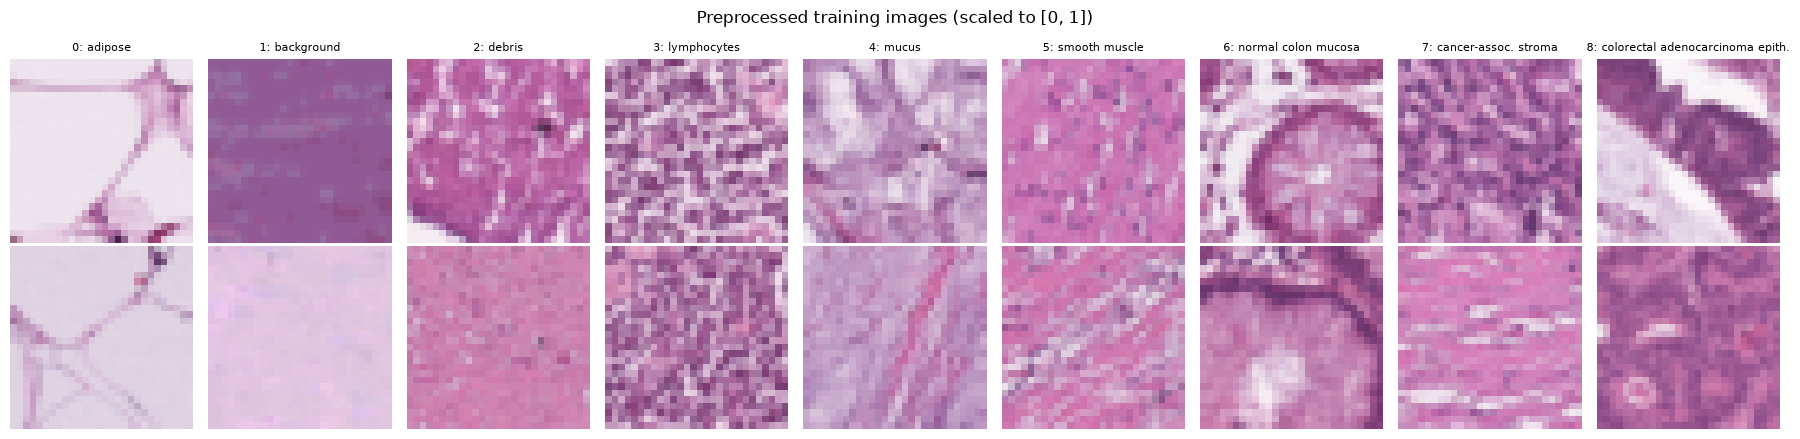

In [5]:
# Pixel range and per-channel mean after scaling
channel_means = X_fit_cnn.mean(axis=(0, 1, 2))
print(f"Pixel range: [{X_fit_cnn.min():.1f}, {X_fit_cnn.max():.1f}]")
print("Per-channel mean (R, G, B):", np.round(channel_means, 3))

# Two preprocessed training images from each class
fig, axes = plt.subplots(2, NUM_CLASSES_CNN, figsize=(18, 4.5))
for class_id, class_name in enumerate(CLASS_NAMES_CNN):
    class_rows = np.flatnonzero(y_fit_cnn == class_id)[:2]
    for row, sample in enumerate(class_rows):
        axes[row, class_id].imshow(X_fit_cnn[sample])
        axes[row, class_id].axis("off")
    axes[0, class_id].set_title(f"{class_id}: {class_name}", fontsize=8)

fig.suptitle("Preprocessed training images (scaled to [0, 1])")
plt.tight_layout()
plt.show()

## 2. Algorithm design and setup

### Algorithm of choice from first six weeks of course

### Fully connected neural network

### Convolutional neural network

The CNN takes the scaled 28×28×3 images directly. It has two convolutional blocks followed by a small fully connected classifier:

| Layer | Details |
| --- | --- |
| Block 1 | Conv2D (`base_filters` filters, 3×3, same padding, ReLU) → MaxPool 2×2 → Dropout |
| Block 2 | Conv2D (2 × `base_filters`, 3×3, same padding, ReLU) → MaxPool 2×2 → Dropout |
| Classifier | Flatten (7×7×channels) → Dense 128 + ReLU → Dropout → Dense 9 + softmax |

**Why this design:**
- Two blocks reduce the image from 28×28 to 7×7. The receptive field then covers a large part of each tissue patch, while the model stays small enough to tune on a CPU.
- The number of filters doubles in the second block because the feature map is smaller, which is the usual way to keep the computation per layer balanced.
- 3×3 kernels with "same" padding keep the borders of these small images.
- Max pooling halves the resolution and makes the features tolerant to small shifts. Dropout is the regularisation option tested in the search.
- The model uses the Adam optimiser and sparse categorical cross-entropy, because the labels are integer class IDs (the same choice as the MLP).

**Rough experiments that shaped the design** (4-epoch trial runs on the shared split):
- **Batch normalisation was tried and removed.** With BN after each convolution, accuracy in inference mode stayed around 0.61, *even on the training images*, while the same network reached about 0.80 on the validation images when it used per-batch statistics. The model therefore did not generalise poorly: BN's stored running statistics did not match what the network had learned. Without BN, validation accuracy rose steadily (0.53 → 0.69 over the first four epochs) and tracked training accuracy.
- **Two convolutions per block took noticeably longer per epoch** on this CPU. In the early timing runs (which still had BN), it was about 21 s vs 16 s with 16 filters, and 55 s vs 33 s with 32 filters. That would have limited how many configurations could be searched, so each block uses one convolution.

In [6]:
def build_cnn(
    input_shape,
    num_classes,
    base_filters=32,
    dropout_rate=0.3,
    learning_rate=0.001,
    kernel_size=3,
    dense_units=128,
):
    """Build and compile a configurable two-block CNN classifier."""
    model = keras.Sequential(name="cnn")
    model.add(keras.Input(shape=input_shape))

    # Convolutional blocks; the second block doubles the filters.
    for block, filters in enumerate((base_filters, base_filters * 2), start=1):
        model.add(layers.Conv2D(
            filters, kernel_size, padding="same", activation="relu",
            name=f"conv{block}",
        ))
        model.add(layers.MaxPooling2D(pool_size=2, name=f"maxpool{block}"))
        model.add(layers.Dropout(dropout_rate, name=f"dropout{block}"))

    # Fully connected classifier
    model.add(layers.Flatten(name="flatten"))
    model.add(layers.Dense(dense_units, activation="relu", name="dense"))
    model.add(layers.Dropout(dropout_rate, name="dropout_dense"))
    model.add(layers.Dense(num_classes, activation="softmax", name="output"))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    return model


# Create an initial model and display its architecture.
keras.utils.set_random_seed(SEED_CNN)

initial_cnn = build_cnn(
    input_shape=INPUT_SHAPE_CNN,
    num_classes=NUM_CLASSES_CNN,
)

initial_cnn.summary()

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 28, 28, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool1 (MaxPooling2D)         │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (Dropout)              │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool2 (MaxPooling2D)         │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout2 (Dropout)              │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_dense (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,089 (1.61 MB)

 Trainable params: 422,089 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Hyperparameter tuning

### Algorithm of choice from first six weeks of course

### Fully connected neural network

### Convolutional neural network

In [7]:
# Compare three hyperparameters across eight configurations.
param_grid_cnn = {
    "base_filters": [16, 32],
    "dropout_rate": [0.0, 0.3],
    "learning_rate": [0.001, 0.0003],
}

MAX_EPOCHS_CNN = 30
BATCH_SIZE_CNN = 128
PATIENCE_CNN = 5

configs_cnn = list(ParameterGrid(param_grid_cnn))
print("Number of configurations:", len(configs_cnn))

Number of configurations: 8


We evaluate eight configurations by varying three hyperparameters:

- **Number of filters** (`base_filters` 16 or 32; the second block uses twice as many). This controls how many local patterns each layer can detect, and so the capacity and the runtime of the network.
- **Dropout rate** (0.0 or 0.3). This controls regularisation: dropout randomly switches off units during training, which reduces overfitting.
- **Learning rate** (0.001 or 0.0003). This is the Adam step size: larger steps converge faster, while smaller steps are more stable but need more epochs.

Dropout and learning rate use the same kind of values as the MLP search, so the effect of each hyperparameter can be compared across the two networks. The number of filters is the CNN's counterpart to the MLP's hidden-layer width.

We use a grid search on the shared validation split rather than cross-validation. Each CNN fit takes minutes on a CPU, so 5-fold cross-validation would multiply the runtime by five. The fixed validation split is also exactly the one used to tune the other two models.

All configurations use the same split, random seed, batch size of 128 and a maximum of 30 epochs. Early stopping monitors validation loss with a patience of five epochs and restores the weights with the lowest validation loss. Configurations are ranked by validation macro F1, with accuracy as the secondary criterion (the same rule as the MLP), so each class counts equally despite the class imbalance. Runtime and epoch counts are recorded for every configuration.

**Note:** this search takes about an hour on a CPU. Its outputs are kept, and Section 4 does not depend on these cells.

In [8]:
results_cnn = []
histories_cnn = {}

for trial_id, config in enumerate(configs_cnn, start=1):
    # Start each configuration with a fresh model.
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED_CNN)

    print(f"\nConfiguration {trial_id}/{len(configs_cnn)}: {config}", flush=True)

    model_cnn = build_cnn(
        input_shape=INPUT_SHAPE_CNN,
        num_classes=NUM_CLASSES_CNN,
        **config,
    )

    early_stopping_cnn = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=PATIENCE_CNN,
        restore_best_weights=True,
    )

    start_time = perf_counter()

    history_cnn = model_cnn.fit(
        X_fit_cnn,
        y_fit_cnn,
        validation_data=(X_val_cnn, y_val_cnn),
        epochs=MAX_EPOCHS_CNN,
        batch_size=BATCH_SIZE_CNN,
        callbacks=[early_stopping_cnn],
        shuffle=True,
        verbose=0,
    )

    fit_seconds = perf_counter() - start_time

    # Evaluate the restored (best-epoch) model on the validation set.
    val_probabilities = model_cnn.predict(X_val_cnn, batch_size=512, verbose=0)
    val_predictions = np.argmax(val_probabilities, axis=1)

    val_accuracy = accuracy_score(y_val_cnn, val_predictions)
    val_macro_f1 = f1_score(
        y_val_cnn, val_predictions, average="macro", zero_division=0,
    )

    best_epoch = int(np.argmin(history_cnn.history["val_loss"]) + 1)
    epochs_run = len(history_cnn.history["loss"])

    results_cnn.append({
        "trial": trial_id,
        **config,
        "n_params": model_cnn.count_params(),
        "best_epoch": best_epoch,
        "epochs_run": epochs_run,
        "train_accuracy_at_best": history_cnn.history["accuracy"][best_epoch - 1],
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1,
        "fit_seconds": fit_seconds,
        "seconds_per_epoch": fit_seconds / epochs_run,
    })

    # Keep learning curves for later plots.
    histories_cnn[trial_id] = history_cnn.history

    print(
        f"Validation accuracy: {val_accuracy:.4f} | "
        f"Macro F1: {val_macro_f1:.4f} | "
        f"Best epoch: {best_epoch}/{epochs_run} | "
        f"Time: {fit_seconds:.1f}s",
        flush=True,
    )

# Rank configurations by macro F1, then accuracy.
results_df_cnn = pd.DataFrame(results_cnn).sort_values(
    by=["val_macro_f1", "val_accuracy"],
    ascending=[False, False],
).reset_index(drop=True)

results_df_cnn.round(4)


Configuration 1/8: {'base_filters': 16, 'dropout_rate': 0.0, 'learning_rate': 0.001}


Validation accuracy: 0.7894 | Macro F1: 0.7856 | Best epoch: 15/20 | Time: 98.0s



Configuration 2/8: {'base_filters': 16, 'dropout_rate': 0.0, 'learning_rate': 0.0003}


Validation accuracy: 0.7730 | Macro F1: 0.7683 | Best epoch: 30/30 | Time: 130.4s



Configuration 3/8: {'base_filters': 16, 'dropout_rate': 0.3, 'learning_rate': 0.001}


...


Configuration 7/8: {'base_filters': 32, 'dropout_rate': 0.3, 'learning_rate': 0.001}


Validation accuracy: 0.8209 | Macro F1: 0.8152 | Best epoch: 26/30 | Time: 277.3s



Configuration 8/8: {'base_filters': 32, 'dropout_rate': 0.3, 'learning_rate': 0.0003}


Validation accuracy: 0.7769 | Macro F1: 0.7677 | Best epoch: 23/28 | Time: 272.7s


,trial,base_filters,dropout_rate,learning_rate,n_params,best_epoch,epochs_run,train_accuracy_at_best,val_accuracy,val_macro_f1,fit_seconds,seconds_per_epoch
0,5,32,0.0,0.0010,422089,23,28,0.8705,0.8236,0.8210,244.8775,8.7456
1,7,32,0.3,0.0010,422089,26,30,0.8088,0.8209,0.8152,277.2666,9.2422
2,3,16,0.3,0.0010,207081,28,30,0.7835,0.7988,0.7915,147.7367,4.9246
3,1,16,0.0,0.0010,207081,15,20,0.7914,0.7894,0.7856,97.9784,4.8989
4,6,32,0.0,0.0003,422089,30,30,0.8191,0.7806,0.7798,240.1477,8.0049
5,4,16,0.3,0.0003,207081,30,30,0.7555,0.7802,0.7688,171.1670,5.7056
6,2,16,0.0,0.0003,207081,30,30,0.7952,0.7730,0.7683,130.4035,4.3468
7,8,32,0.3,0.0003,422089,23,28,0.7601,0.7769,0.7677,272.6623,9.7379


In [9]:
# Save the search results and learning curves for the group's tables and plots.
results_df_cnn.to_csv(RESULTS_DIR_CNN / "cnn_tuning_results.csv", index=False)

history_rows_cnn = [
    {"trial": trial_id, "epoch": epoch + 1,
     **{metric: values[epoch] for metric, values in history.items()}}
    for trial_id, history in histories_cnn.items()
    for epoch in range(len(history["loss"]))
]
pd.DataFrame(history_rows_cnn).to_csv(
    RESULTS_DIR_CNN / "cnn_tuning_histories.csv", index=False
)

print("Saved:", sorted(path.name for path in RESULTS_DIR_CNN.glob("cnn_tuning_*.csv")))

Saved: ['cnn_tuning_histories.csv', 'cnn_tuning_results.csv']


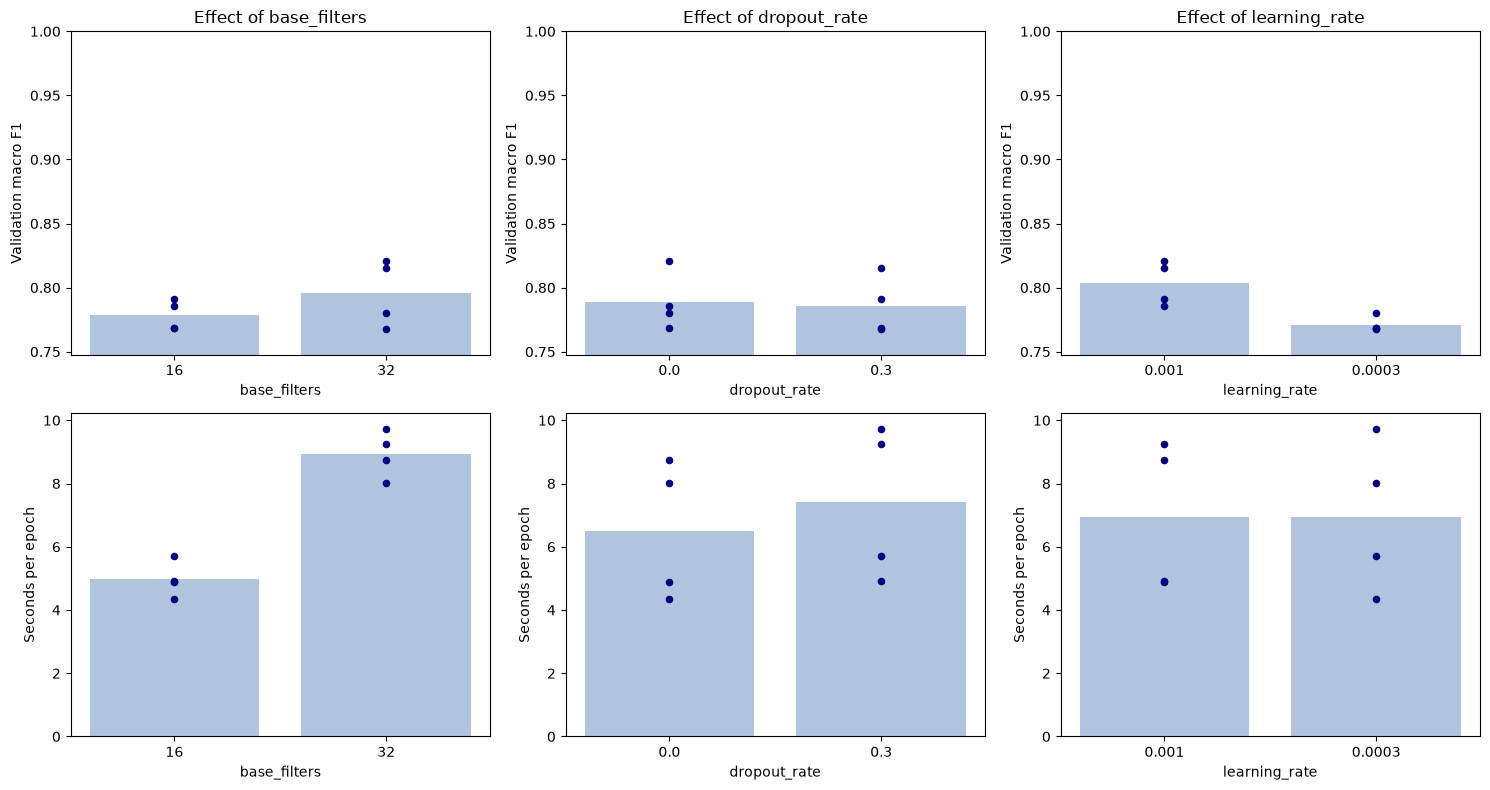

In [10]:
# Effect of each hyperparameter: mean over the four configurations sharing a value,
# with the individual configurations shown as points.
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for col, name in enumerate(param_grid_cnn):
    values = param_grid_cnn[name]
    labels = [str(value) for value in values]

    for row, (metric, ylabel) in enumerate([
        ("val_macro_f1", "Validation macro F1"),
        ("seconds_per_epoch", "Seconds per epoch"),
    ]):
        ax = axes[row, col]
        groups = [results_df_cnn.loc[results_df_cnn[name] == value, metric] for value in values]
        ax.bar(labels, [group.mean() for group in groups], color="lightsteelblue", label="Mean")
        for position, group in enumerate(groups):
            ax.scatter([position] * len(group), group, color="navy", zorder=3, s=20)
        ax.set_xlabel(name)
        ax.set_ylabel(ylabel)

    low = results_df_cnn["val_macro_f1"].min()
    axes[0, col].set_ylim(low - 0.02, 1.0)
    axes[0, col].set_title(f"Effect of {name}")

plt.tight_layout()
plt.show()

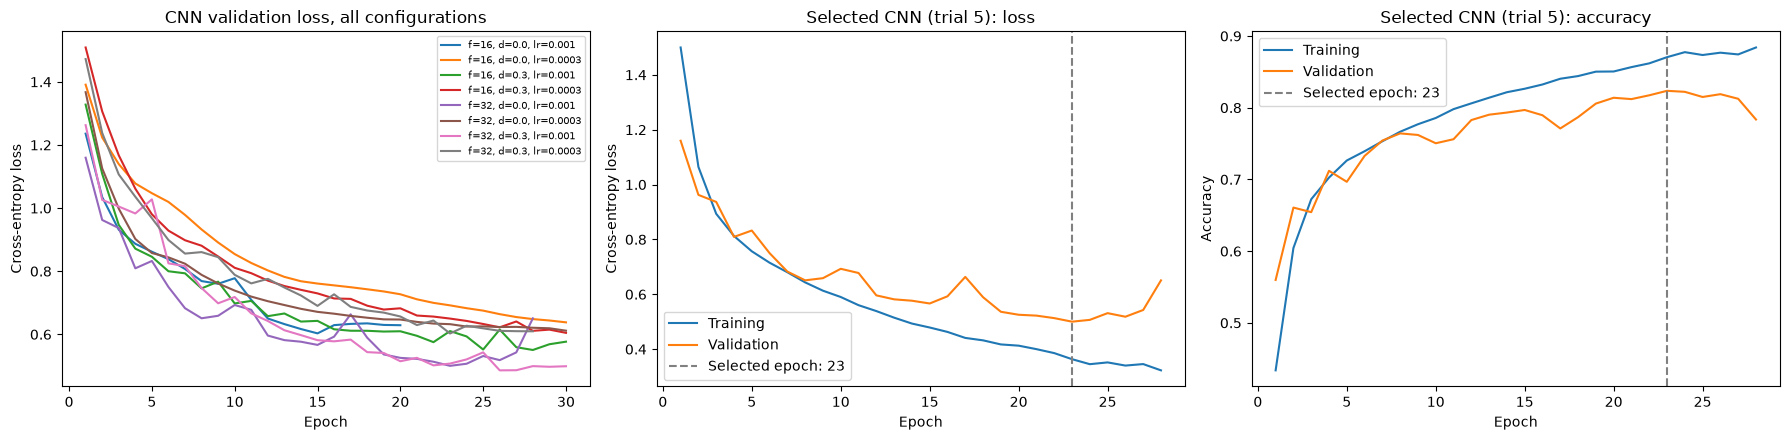

In [11]:
# Validation loss of every configuration, and the learning curves of the selected one.
best_trial_cnn = int(results_df_cnn.iloc[0]["trial"])
best_epoch_cnn = int(results_df_cnn.iloc[0]["best_epoch"])
best_history_cnn = histories_cnn[best_trial_cnn]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

for _, row in results_df_cnn.sort_values("trial").iterrows():
    history = histories_cnn[int(row["trial"])]
    axes[0].plot(
        range(1, len(history["val_loss"]) + 1), history["val_loss"],
        label=(f"f={int(row['base_filters'])}, d={row['dropout_rate']}, "
               f"lr={row['learning_rate']}"),
    )
axes[0].set_title("CNN validation loss, all configurations")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend(fontsize=7)

epochs_cnn = range(1, len(best_history_cnn["loss"]) + 1)
for ax, metric, ylabel in [
    (axes[1], "loss", "Cross-entropy loss"),
    (axes[2], "accuracy", "Accuracy"),
]:
    ax.plot(epochs_cnn, best_history_cnn[metric], label="Training")
    ax.plot(epochs_cnn, best_history_cnn[f"val_{metric}"], label="Validation")
    ax.axvline(best_epoch_cnn, color="grey", linestyle="--",
               label=f"Selected epoch: {best_epoch_cnn}")
    ax.set_title(f"Selected CNN (trial {best_trial_cnn}): {metric}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend()

plt.tight_layout()
plt.show()

<!-- TUNING-DISCUSSION -->

## 4. Final models
In this section, please ensure to include cells to train each model with its best hyperparmater combination independently of the hyperparameter tuning cells, i.e. don't rely on the hyperparameter tuning cells having been run.

### Algorithm of choice from first six weeks of course

### Fully connected neural network

### Convolutional neural network

The final CNN is trained from scratch on **all 32,000 training images** with the configuration selected in Section 3. It runs for the fixed number of epochs at which that configuration reached its lowest validation loss. The settings are written out explicitly below, so this section runs even if the tuning cells are skipped. The test set is used only here, once, for the final evaluation.

In [12]:
# Configuration selected using validation macro F1 (Section 3).
FINAL_CONFIG_CNN = {
    "base_filters": 32,
    "dropout_rate": 0.0,
    "learning_rate": 0.001,
}
FINAL_EPOCHS_CNN = 23
FINAL_BATCH_SIZE_CNN = 128

In [13]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED_CNN)

start_time_cnn = perf_counter()

# Preprocess the complete training set (fixed scaling, nothing is fitted).
X_train_final_cnn = preprocess_cnn(X_train_all_cnn)

# Train a fresh model using all training samples.
final_model_cnn = build_cnn(
    input_shape=INPUT_SHAPE_CNN,
    num_classes=NUM_CLASSES_CNN,
    **FINAL_CONFIG_CNN,
)

final_history_cnn = final_model_cnn.fit(
    X_train_final_cnn,
    y_train_all_cnn,
    epochs=FINAL_EPOCHS_CNN,
    batch_size=FINAL_BATCH_SIZE_CNN,
    shuffle=True,
    verbose=0,
)

final_fit_seconds_cnn = perf_counter() - start_time_cnn

print("Final configuration:", FINAL_CONFIG_CNN)
print("Trainable parameters:", final_model_cnn.count_params())
print("Training samples:", len(y_train_all_cnn))
print("Training epochs:", FINAL_EPOCHS_CNN)
print(f"Preprocessing and training time: {final_fit_seconds_cnn:.2f}s "
      f"({final_fit_seconds_cnn / FINAL_EPOCHS_CNN:.1f}s per epoch)")

Final configuration: {'base_filters': 32, 'dropout_rate': 0.0, 'learning_rate': 0.001}
Trainable parameters: 422089
Training samples: 32000
Training epochs: 23
Preprocessing and training time: 211.50s (9.2s per epoch)


In [14]:
start_time_cnn = perf_counter()

# Apply the same fixed preprocessing to the held-out test images.
X_test_cnn = preprocess_cnn(X_test_img_cnn)

test_probabilities_cnn = final_model_cnn.predict(X_test_cnn, batch_size=512, verbose=0)
test_predictions_cnn = np.argmax(test_probabilities_cnn, axis=1)

test_predict_seconds_cnn = perf_counter() - start_time_cnn

test_metrics_cnn = {
    "accuracy": accuracy_score(y_test_cnn, test_predictions_cnn),
    "macro_f1": f1_score(y_test_cnn, test_predictions_cnn, average="macro", zero_division=0),
    "weighted_f1": f1_score(y_test_cnn, test_predictions_cnn, average="weighted", zero_division=0),
    "macro_precision": precision_score(y_test_cnn, test_predictions_cnn, average="macro", zero_division=0),
    "macro_recall": recall_score(y_test_cnn, test_predictions_cnn, average="macro", zero_division=0),
}

for name, value in test_metrics_cnn.items():
    print(f"Test {name.replace('_', ' ')}: {value:.4f}")
print(f"Test preprocessing and prediction time: {test_predict_seconds_cnn:.2f}s")

print("\nClassification report:")
print(classification_report(
    y_test_cnn,
    test_predictions_cnn,
    target_names=[f"{i} {name}" for i, name in enumerate(CLASS_NAMES_CNN)],
    digits=4,
    zero_division=0,
))

Test accuracy: 0.8040
Test macro f1: 0.7973
Test weighted f1: 0.8016
Test macro precision: 0.8147
Test macro recall: 0.8022
Test preprocessing and prediction time: 1.06s

Classification report:
                                    precision    recall  f1-score   support

                         0 adipose     0.9759    0.9290    0.9519       873
                      1 background     0.9796    0.9534    0.9663       858
                          2 debris     0.5572    0.8221    0.6642       877
                     3 lymphocytes     0.9543    0.9606    0.9575       914
                           4 mucus     0.7967    0.7870    0.7918       737
                   5 smooth muscle     0.7738    0.8106    0.7918      1072
             6 normal colon mucosa     0.6671    0.8196    0.7355       682
            7 cancer-assoc. stroma     0.7616    0.3850    0.5114       813
8 colorectal adenocarcinoma epith.     0.8657    0.7521    0.8049      1174

                          accuracy          

In [15]:
# Export the final CNN results as CSV files for the combined comparison tables.
final_summary_cnn = pd.DataFrame([{
    "model": "CNN",
    "best_hyperparameters": "; ".join(f"{k}={v}" for k, v in FINAL_CONFIG_CNN.items()),
    "epochs": FINAL_EPOCHS_CNN,
    "batch_size": FINAL_BATCH_SIZE_CNN,
    "n_params": final_model_cnn.count_params(),
    "train_samples": len(y_train_all_cnn),
    "train_seconds": final_fit_seconds_cnn,
    "seconds_per_epoch": final_fit_seconds_cnn / FINAL_EPOCHS_CNN,
    "test_predict_seconds": test_predict_seconds_cnn,
    **{f"test_{name}": value for name, value in test_metrics_cnn.items()},
}])
final_summary_cnn.to_csv(RESULTS_DIR_CNN / "cnn_final_results.csv", index=False)

report_cnn = pd.DataFrame(classification_report(
    y_test_cnn, test_predictions_cnn, output_dict=True, zero_division=0,
)).T
per_class_cnn = report_cnn.iloc[:NUM_CLASSES_CNN].copy()
per_class_cnn.insert(0, "class_name", CLASS_NAMES_CNN)
per_class_cnn.index.name = "class_id"
per_class_cnn.to_csv(RESULTS_DIR_CNN / "cnn_classification_report.csv")

confusion_cnn = confusion_matrix(y_test_cnn, test_predictions_cnn, labels=range(NUM_CLASSES_CNN))
pd.DataFrame(
    confusion_cnn,
    index=[f"true_{i}" for i in range(NUM_CLASSES_CNN)],
    columns=[f"pred_{i}" for i in range(NUM_CLASSES_CNN)],
).to_csv(RESULTS_DIR_CNN / "cnn_confusion_matrix.csv")

pd.DataFrame({
    "y_true": y_test_cnn,
    "y_pred": test_predictions_cnn,
    "confidence": test_probabilities_cnn.max(axis=1),
}).to_csv(RESULTS_DIR_CNN / "cnn_test_predictions.csv", index_label="test_index")

print("Saved:", sorted(path.name for path in RESULTS_DIR_CNN.glob("*.csv")))
final_summary_cnn.round(4).T

Saved: ['cnn_classification_report.csv', 'cnn_confusion_matrix.csv', 'cnn_final_results.csv', 'cnn_test_predictions.csv', 'cnn_tuning_histories.csv', 'cnn_tuning_results.csv']


,0
model,CNN
best_hyperparameters,base_filters=32; dropout_rate=0.0; learning_ra...
epochs,23
batch_size,128
n_params,422089
train_samples,32000
train_seconds,211.4952
seconds_per_epoch,9.1954
test_predict_seconds,1.0631
test_accuracy,0.804


#### CNN error analysis

The cells below look at the kinds of mistakes the final CNN makes:
- confusion matrices (counts, and rows normalised to recall),
- the most frequent pairs of confused classes,
- how confident the model is when it is right compared with when it is wrong,
- examples of misclassified test images.

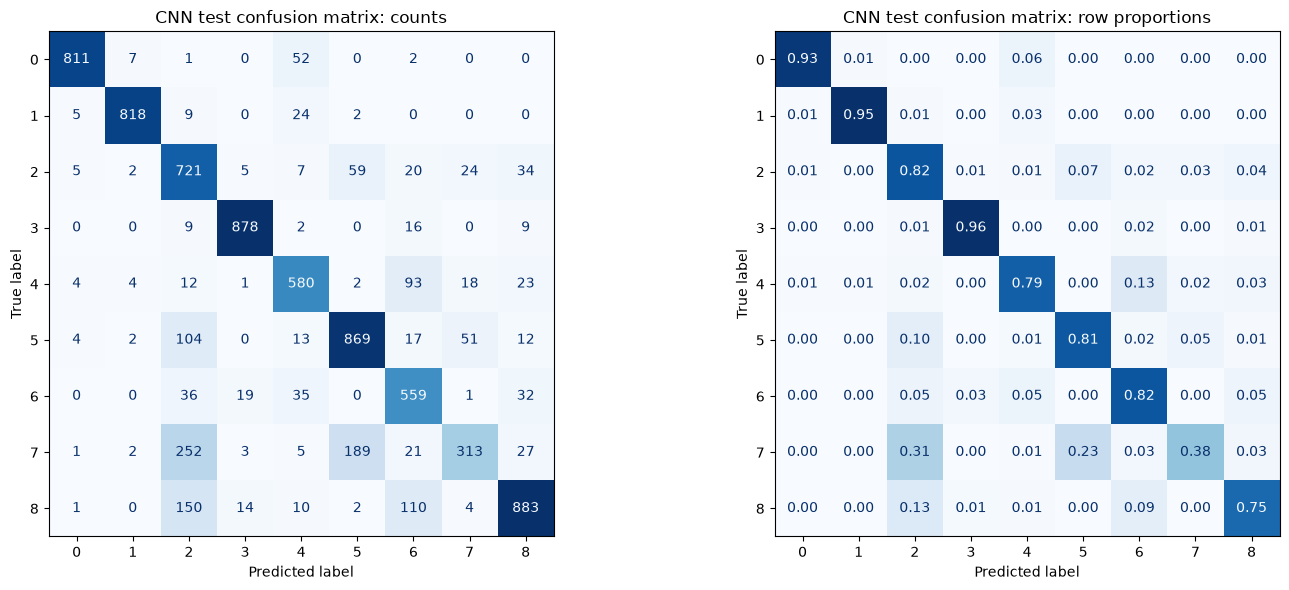

Class IDs: 0 = adipose, 1 = background, 2 = debris, 3 = lymphocytes, 4 = mucus, 5 = smooth muscle, 6 = normal colon mucosa, 7 = cancer-assoc. stroma, 8 = colorectal adenocarcinoma epith.


In [16]:
# Display counts and recall-normalised confusion matrices.
short_names_cnn = [f"{i}" for i in range(NUM_CLASSES_CNN)]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test_cnn, test_predictions_cnn,
    labels=range(NUM_CLASSES_CNN), display_labels=short_names_cnn,
    cmap="Blues", values_format="d", colorbar=False, ax=axes[0],
)
axes[0].set_title("CNN test confusion matrix: counts")

ConfusionMatrixDisplay.from_predictions(
    y_test_cnn, test_predictions_cnn,
    labels=range(NUM_CLASSES_CNN), display_labels=short_names_cnn,
    normalize="true", cmap="Blues", values_format=".2f", colorbar=False, ax=axes[1],
)
axes[1].set_title("CNN test confusion matrix: row proportions")

plt.tight_layout()
plt.show()

print("Class IDs:", ", ".join(f"{i} = {name}" for i, name in enumerate(CLASS_NAMES_CNN)))

In [17]:
# Most frequent confusions (true class -> predicted class)
off_diagonal_cnn = [
    {
        "true": f"{i} {CLASS_NAMES_CNN[i]}",
        "predicted": f"{j} {CLASS_NAMES_CNN[j]}",
        "count": int(confusion_cnn[i, j]),
        "share_of_true_class": confusion_cnn[i, j] / confusion_cnn[i].sum(),
    }
    for i in range(NUM_CLASSES_CNN)
    for j in range(NUM_CLASSES_CNN)
    if i != j and confusion_cnn[i, j] > 0
]
top_confusions_cnn = (
    pd.DataFrame(off_diagonal_cnn)
    .sort_values("count", ascending=False)
    .head(8)
    .reset_index(drop=True)
)
top_confusions_cnn.to_csv(RESULTS_DIR_CNN / "cnn_top_confusions.csv", index=False)

n_errors_cnn = int((test_predictions_cnn != y_test_cnn).sum())
print(f"Misclassified test images: {n_errors_cnn} of {len(y_test_cnn)}")
print(f"Share of all errors in the top 8 pairs: {top_confusions_cnn['count'].sum() / n_errors_cnn:.1%}")
top_confusions_cnn.round(3)

Misclassified test images: 1568 of 8000
Share of all errors in the top 8 pairs: 64.3%


,true,predicted,count,share_of_true_class
0,7 cancer-assoc. stroma,2 debris,252,0.310
1,7 cancer-assoc. stroma,5 smooth muscle,189,0.232
2,8 colorectal adenocarcinoma epith.,2 debris,150,0.128
3,8 colorectal adenocarcinoma epith.,6 normal colon mucosa,110,0.094
4,5 smooth muscle,2 debris,104,0.097
5,4 mucus,6 normal colon mucosa,93,0.126
6,2 debris,5 smooth muscle,59,0.067
7,0 adipose,4 mucus,52,0.060


Mean confidence when correct:   0.895
Mean confidence when incorrect: 0.655
Errors made with confidence > 0.9: 11.9% of all errors


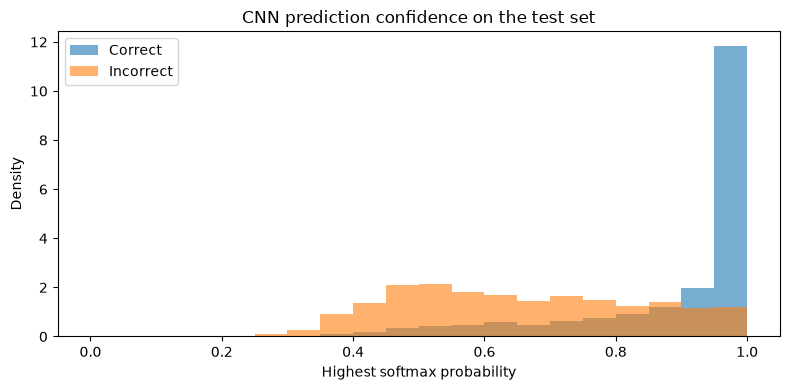

In [18]:
# Confidence (highest softmax probability) of correct and incorrect predictions
confidence_cnn = test_probabilities_cnn.max(axis=1)
correct_mask_cnn = test_predictions_cnn == y_test_cnn

print(f"Mean confidence when correct:   {confidence_cnn[correct_mask_cnn].mean():.3f}")
print(f"Mean confidence when incorrect: {confidence_cnn[~correct_mask_cnn].mean():.3f}")
print(f"Errors made with confidence > 0.9: "
      f"{(confidence_cnn[~correct_mask_cnn] > 0.9).mean():.1%} of all errors")

plt.figure(figsize=(8, 4))
bins = np.linspace(0, 1, 21)
plt.hist(confidence_cnn[correct_mask_cnn], bins=bins, alpha=0.6, density=True, label="Correct")
plt.hist(confidence_cnn[~correct_mask_cnn], bins=bins, alpha=0.6, density=True, label="Incorrect")
plt.xlabel("Highest softmax probability")
plt.ylabel("Density")
plt.title("CNN prediction confidence on the test set")
plt.legend()
plt.tight_layout()
plt.show()

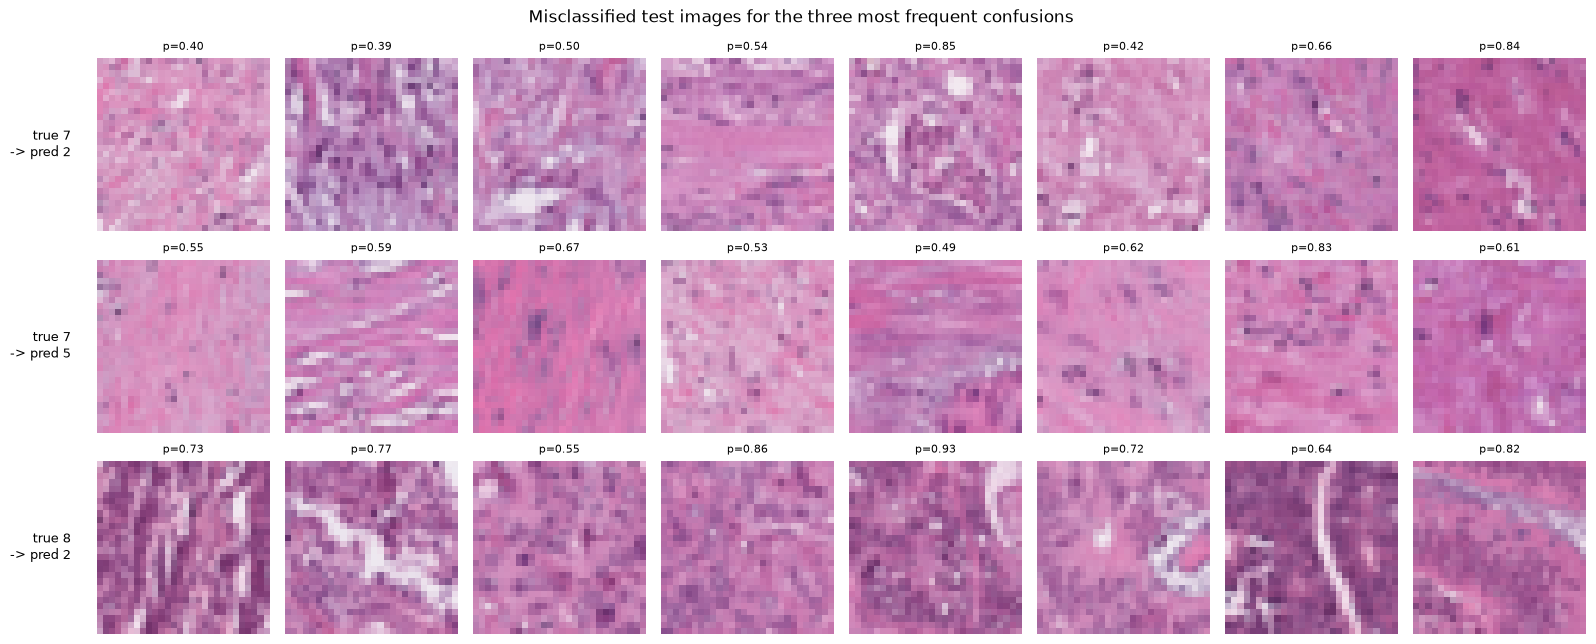

In [19]:
# Misclassified examples from the most frequent confusion pairs
rng_cnn = np.random.default_rng(SEED_CNN)
fig, axes = plt.subplots(3, 8, figsize=(16, 6.6))

for row, (_, pair) in enumerate(top_confusions_cnn.head(3).iterrows()):
    true_id = int(pair["true"].split()[0])
    pred_id = int(pair["predicted"].split()[0])
    pair_rows = np.flatnonzero((y_test_cnn == true_id) & (test_predictions_cnn == pred_id))
    chosen = rng_cnn.choice(pair_rows, size=min(8, len(pair_rows)), replace=False)

    for col in range(8):
        ax = axes[row, col]
        ax.axis("off")
        if col < len(chosen):
            ax.imshow(X_test_img_cnn[chosen[col]])
            ax.set_title(f"p={confidence_cnn[chosen[col]]:.2f}", fontsize=8)
    axes[row, 0].text(
        -0.15, 0.5,
        f"true {true_id}\n-> pred {pred_id}",
        transform=axes[row, 0].transAxes, ha="right", va="center", fontsize=9,
    )

fig.suptitle("Misclassified test images for the three most frequent confusions")
plt.tight_layout()
plt.show()

<!-- FINAL-DISCUSSION -->

## 5. AI Acknowledgement
Include acknowledgement of AI usage here.

<!-- AI-ACK -->